# Selección de variables en Regresión Lineal Múltiple
## *Forward*, *Backward*, *Stepwise* y búsqueda exhaustiva — con todo lo que debe ir antes

**Curso:** Regresión · **Base de trabajo:** *Boston Housing* (506 sectores censales de Boston, 1970)

---

### ¿De qué trata esta clase?

Cuando tenemos muchos predictores candidatos, surge una pregunta inevitable:

> **¿Cuáles variables deben quedarse en el modelo y cuáles sobran?**

Responderla bien no es "correr un algoritmo". Es un proceso con orden:

| Paso | Qué hacemos | Por qué |
|---|---|---|
| 1 | Entender el problema y los datos | Una variable no se selecciona si no sabemos qué mide |
| 2 | Análisis exploratorio (EDA) | Detectar asimetrías, atípicos, relaciones no lineales y colinealidad |
| 3 | Separar entrenamiento y prueba | Para evaluar con honestidad lo que el modelo predice |
| 4 | Ajustar y **diagnosticar** el modelo completo | La selección se hace sobre un modelo que tenga sentido |
| 5 | **Seleccionar variables** (*forward*, *backward*, *stepwise*, exhaustiva) | El tema central de hoy |
| 6 | Comparar, validar y diagnosticar el modelo final | Ningún algoritmo tiene la última palabra |

### Objetivos de aprendizaje

Al terminar la sesión, el estudiante podrá:

1. Explicar **por qué** seleccionar variables (parsimonia, sobreajuste, colinealidad, interpretabilidad).
2. Describir y ejecutar **paso a paso** la selección hacia adelante, hacia atrás y por pasos.
3. Usar y distinguir los criterios $p$-valor, $R^2_{aj}$, AIC, BIC y error de validación cruzada.
4. Comparar los modelos obtenidos y elegir uno **con criterio estadístico y sustantivo**.
5. Reconocer los **peligros** de la selección automática (p-valores optimistas, inestabilidad).

> 💡 **Cómo usar el cuadernillo:** ejecute las celdas en orden (`Shift + Enter`). Las celdas marcadas con ✏️ son para que usted modifique y experimente.

---
# PARTE 0. Preparación del entorno

In [1]:
# Si alguna librería no está instalada, quite el '#' de la siguiente línea y ejecútela una vez:
# %pip install pandas numpy matplotlib seaborn statsmodels scikit-learn scipy

In [2]:
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

SEMILLA = 2026          # ✏️ semilla para que todos obtengamos los mismos resultados
np.random.seed(SEMILLA)
print("Entorno listo ✔")

Entorno listo ✔


In [3]:
def ruta_datos(nombre):
    '''Busca el archivo en ../datos, ./datos o la carpeta actual.'''
    for carpeta in [Path("../datos"), Path("datos"), Path(".")]:
        if (carpeta / nombre).exists():
            return carpeta / nombre
    raise FileNotFoundError(f"No encuentro {nombre}. Colóquelo en la carpeta 'datos' del repositorio.")

---
# PARTE 1. ¿Por qué seleccionar variables?

Imagine que tenemos $k$ predictores candidatos. El modelo completo es

$$
Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \cdots + \beta_k X_k + \varepsilon,
\qquad \varepsilon \sim N(0,\sigma^2).
$$

¿Por qué no dejarlas todas? Porque cada variable que entra **cuesta algo**:

| Problema | Qué pasa | Consecuencia |
|---|---|---|
| **Sobreajuste** | El modelo "memoriza" el ruido de la muestra | Predice peor datos nuevos |
| **Varianza de los estimadores** | Cada parámetro extra se estima con error | Intervalos más anchos, coeficientes inestables |
| **Multicolinealidad** | Predictores que dicen lo mismo | Signos absurdos, errores estándar inflados |
| **Interpretabilidad** | 12 coeficientes vs. 5 | Un modelo más simple se comunica mejor |
| **Costo** | Medir variables cuesta dinero y tiempo | En la práctica conviene medir menos |

Pero quitar variables **también** cuesta: si eliminamos una variable relevante, los coeficientes de las demás quedan **sesgados** (sesgo por variable omitida).

> 🎯 **El dilema sesgo–varianza:** pocos predictores → sesgo; demasiados → varianza. La selección de variables busca el punto de equilibrio. Ese es el principio de **parsimonia** (navaja de Ockham): *el modelo más simple que explique adecuadamente los datos*.

### Demostración: el $R^2$ siempre sube… aunque agreguemos basura

Vamos a crear un ejemplo pequeño: una respuesta que depende de **2** variables reales, y le vamos añadiendo variables de **puro ruido**.

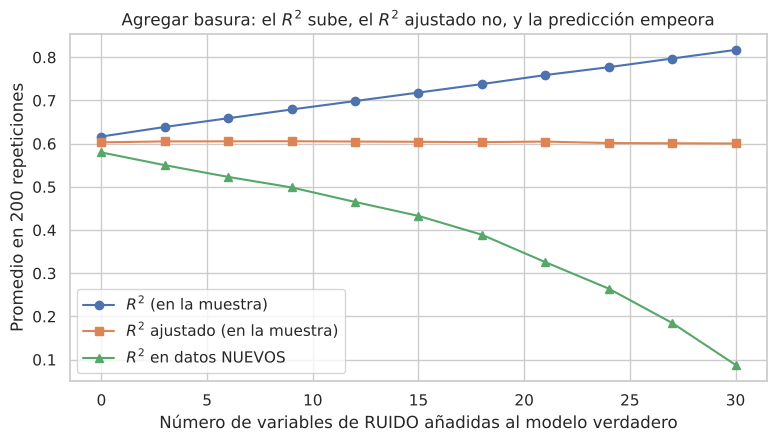

In [4]:
rng = np.random.default_rng(SEMILLA)
n, reps = 60, 200                       # 60 observaciones; repetimos el experimento 200 veces y promediamos
niveles_ruido = list(range(0, 31, 3))
acum = {k: [] for k in niveles_ruido}
for _ in range(reps):
    x1, x2 = rng.normal(size=n), rng.normal(size=n)
    y_demo = 3 + 2 * x1 - 1.5 * x2 + rng.normal(scale=2, size=n)          # el modelo VERDADERO usa solo x1 y x2
    ruido = rng.normal(size=(n, 30))                                       # 30 variables que NO tienen nada que ver
    # datos NUEVOS del mismo proceso, para medir la capacidad predictiva real
    z1, z2 = rng.normal(size=n), rng.normal(size=n)
    y_nuevo = 3 + 2 * z1 - 1.5 * z2 + rng.normal(scale=2, size=n)
    ruido_nuevo = rng.normal(size=(n, 30))
    for k in niveles_ruido:
        m = sm.OLS(y_demo, sm.add_constant(np.column_stack([x1, x2, ruido[:, :k]]))).fit()
        pred = m.predict(sm.add_constant(np.column_stack([z1, z2, ruido_nuevo[:, :k]])))
        r2_nuevo = 1 - np.sum((y_nuevo - pred) ** 2) / np.sum((y_nuevo - y_nuevo.mean()) ** 2)
        acum[k].append((m.rsquared, m.rsquared_adj, r2_nuevo))
demo = pd.DataFrame({k: np.mean(v, axis=0) for k, v in acum.items()},
                    index=["R2", "R2_ajustado", "R2_datos_nuevos"]).T

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(demo.index, demo.R2, "o-", label="$R^2$ (en la muestra)")
ax.plot(demo.index, demo.R2_ajustado, "s-", label="$R^2$ ajustado (en la muestra)")
ax.plot(demo.index, demo.R2_datos_nuevos, "^-", label="$R^2$ en datos NUEVOS")
ax.set_xlabel("Número de variables de RUIDO añadidas al modelo verdadero")
ax.set_ylabel("Promedio en 200 repeticiones")
ax.set_title("Agregar basura: el $R^2$ sube, el $R^2$ ajustado no, y la predicción empeora")
ax.legend(); plt.show()

**Lección:** el $R^2$ **nunca baja** al agregar variables (aun si son ruido puro), así que **no sirve** para elegir entre modelos de distinto tamaño. El $R^2$ ajustado, en promedio, no premia la basura. Y lo más importante: la capacidad de **predecir datos nuevos** se deteriora con cada variable inútil: eso es el **sobreajuste**. Necesitamos criterios que **penalicen la complejidad**:

| Criterio | Fórmula | Se prefiere | Idea |
|---|---|---|---|
| $R^2$ ajustado | $1-\dfrac{SC_{Res}/(n-p)}{SC_T/(n-1)}$ | **Mayor** | Corrige el $R^2$ por los grados de libertad |
| AIC (Akaike) | $n\ln\!\left(\dfrac{SC_{Res}}{n}\right)+2p$ | **Menor** | Ajuste + penalización de $2$ por parámetro |
| BIC (Schwarz) | $n\ln\!\left(\dfrac{SC_{Res}}{n}\right)+p\ln(n)$ | **Menor** | Penaliza más fuerte ($\ln n > 2$ si $n>7$) → modelos más pequeños |
| $C_p$ de Mallows | $\dfrac{SC_{Res,p}}{\hat\sigma^2_{completo}}-(n-2p)$ | $C_p \approx p$ y pequeño | Estima el error de predicción |
| Prueba $F$ parcial / $p$-valor | ver Parte 6 | $p<\alpha$ para entrar | Contraste de hipótesis entre modelos anidados |
| Error de validación cruzada | RMSE fuera de muestra | **Menor** | Mide directamente la capacidad predictiva |

donde $p$ = número de parámetros (incluye el intercepto) y $n$ = número de observaciones.

> ⚠️ AIC y BIC sólo se comparan entre modelos ajustados **sobre los mismos datos y la misma respuesta** (no compare un AIC de $Y$ con uno de $\log Y$).

---
# PARTE 2. El problema y los datos

**Pregunta de investigación:** ¿Qué características de un sector censal se asocian con el **valor mediano de las viviendas** (`MEDV`, en miles de dólares) y cuáles bastan para predecirlo?

### Diccionario de variables

| Variable | Descripción |
|---|---|
| `CRIM` | Tasa de criminalidad per cápita |
| `ZN` | % de suelo residencial con lotes > 25 000 pies² |
| `INDUS` | % de acres de negocios no minoristas (industria) |
| `CHAS` | 1 si el sector limita con el río Charles; 0 en otro caso (*dummy*) |
| `NOX` | Concentración de óxidos nítricos (partes por 10 millones) |
| `RM` | Número promedio de habitaciones por vivienda |
| `AGE` | % de viviendas ocupadas por propietarios construidas antes de 1940 |
| `DIS` | Distancia ponderada a 5 centros de empleo |
| `RAD` | Índice de accesibilidad a autopistas radiales |
| `TAX` | Tasa de impuesto predial por cada 10 000 USD |
| `PTRATIO` | Razón alumnos/profesor |
| `LSTAT` | % de población de estatus socioeconómico bajo |
| `MEDV` | **Respuesta:** valor mediano de viviendas ocupadas por propietarios (miles USD) |

> ⚖️ **Nota ética.** La base original incluye la variable `B` $=1000(B_k-0.63)^2$, construida a partir de la proporción de población afrodescendiente bajo un supuesto de segregación racial. Esa codificación incorpora un sesgo racial explícito y por eso **no la usaremos como predictor**. Elegir variables también es una decisión ética, no sólo técnica.

In [5]:
df_original = pd.read_csv(ruta_datos("boston_house_prices.csv"), skiprows=1)   # la 1.ª fila del archivo es un encabezado extra
df = df_original.drop(columns="B")                                              # ver nota ética

RESPUESTA = "MEDV"
PREDICTORES = [c for c in df.columns if c != RESPUESTA]

print(f"Observaciones: {df.shape[0]}  |  Predictores candidatos: {len(PREDICTORES)}")
df.head()

Observaciones: 506  |  Predictores candidatos: 12


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.0063,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.0273,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.0273,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.0324,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.0691,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


---
# PARTE 3. Análisis exploratorio (EDA)

Antes de seleccionar, **miramos**. Lo que buscamos:

1. Calidad: faltantes, duplicados, valores imposibles.
2. Forma de la respuesta: ¿simétrica? ¿acotada?
3. Relación de cada predictor con la respuesta: ¿lineal? ¿curva?
4. Relación **entre predictores**: ¿hay variables redundantes? (colinealidad)

## 3.1 Calidad de los datos

In [6]:
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "valores_distintos": df.nunique(),
    "mínimo": df.min(),
    "máximo": df.max(),
})
print("Filas duplicadas:", df.duplicated().sum())
calidad

Filas duplicadas: 0


,tipo,faltantes,valores_distintos,mínimo,máximo
CRIM,float64,0,504,0.0063,88.9762
ZN,float64,0,26,0.0000,100.0000
INDUS,float64,0,76,0.4600,27.7400
CHAS,int64,0,2,0.0000,1.0000
NOX,float64,0,81,0.3850,0.8710
RM,float64,0,446,3.5610,8.7800
AGE,float64,0,356,2.9000,100.0000
DIS,float64,0,412,1.1296,12.1265
RAD,int64,0,9,1.0000,24.0000
TAX,int64,0,66,187.0000,711.0000


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.6135,8.6015,0.0063,0.0820,0.2565,3.6771,88.9762
ZN,506.0,11.3636,23.3225,0.0000,0.0000,0.0000,12.5000,100.0000
INDUS,506.0,11.1368,6.8604,0.4600,5.1900,9.6900,18.1000,27.7400
CHAS,506.0,0.0692,0.2540,0.0000,0.0000,0.0000,0.0000,1.0000
NOX,506.0,0.5547,0.1159,0.3850,0.4490,0.5380,0.6240,0.8710
RM,506.0,6.2846,0.7026,3.5610,5.8855,6.2085,6.6235,8.7800
AGE,506.0,68.5749,28.1489,2.9000,45.0250,77.5000,94.0750,100.0000
DIS,506.0,3.7950,2.1057,1.1296,2.1002,3.2074,5.1884,12.1265
RAD,506.0,9.5494,8.7073,1.0000,4.0000,5.0000,24.0000,24.0000
TAX,506.0,408.2372,168.5371,187.0000,279.0000,330.0000,666.0000,711.0000


**Para observar:** no hay faltantes ni duplicados. `CHAS` sólo toma 0 y 1 (dicotómica). `RAD` tiene pocos valores distintos (es un índice). `CRIM` tiene media mucho menor que su máximo → **fuerte asimetría**.

## 3.2 La variable respuesta

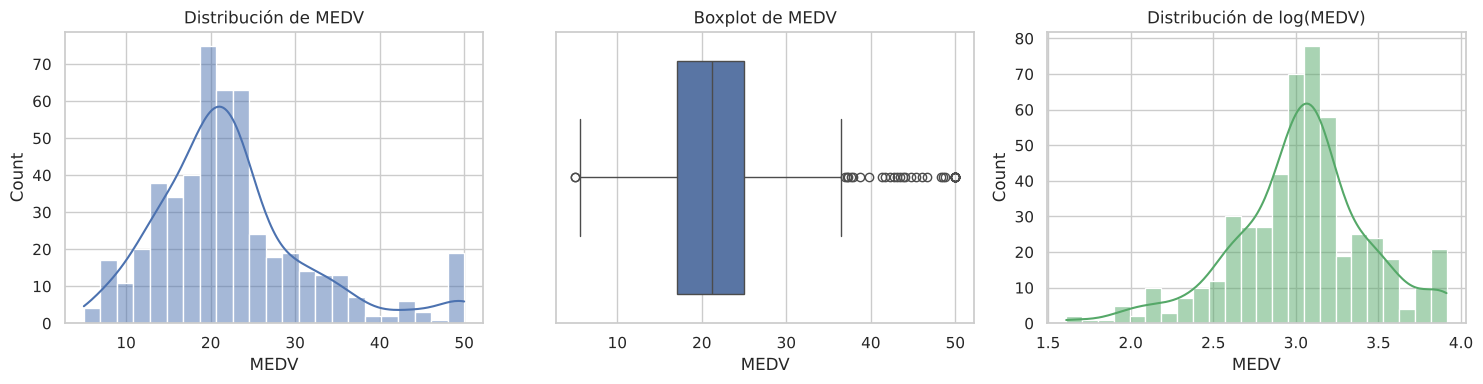

Asimetría MEDV: 1.10   |   Asimetría log(MEDV): -0.33
Viviendas con MEDV = 50 (valor tope): 16


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df[RESPUESTA], kde=True, ax=axes[0])
axes[0].set_title("Distribución de MEDV")
sns.boxplot(x=df[RESPUESTA], ax=axes[1])
axes[1].set_title("Boxplot de MEDV")
sns.histplot(np.log(df[RESPUESTA]), kde=True, ax=axes[2], color="C2")
axes[2].set_title("Distribución de log(MEDV)")
plt.tight_layout(); plt.show()

print(f"Asimetría MEDV: {stats.skew(df[RESPUESTA]):.2f}   |   Asimetría log(MEDV): {stats.skew(np.log(df[RESPUESTA])):.2f}")
print(f"Viviendas con MEDV = 50 (valor tope): {(df[RESPUESTA] == 50).sum()}")

**Interpretación:**
- `MEDV` tiene **asimetría positiva** (cola a la derecha). El logaritmo la reduce bastante.
- Hay **16 sectores con MEDV = 50**: el valor fue **censurado** (topado) en la base original. Es un límite de la medición, no un dato real. Lo dejamos, pero es una limitación que debe declararse en un informe.

## 3.3 Distribución de los predictores

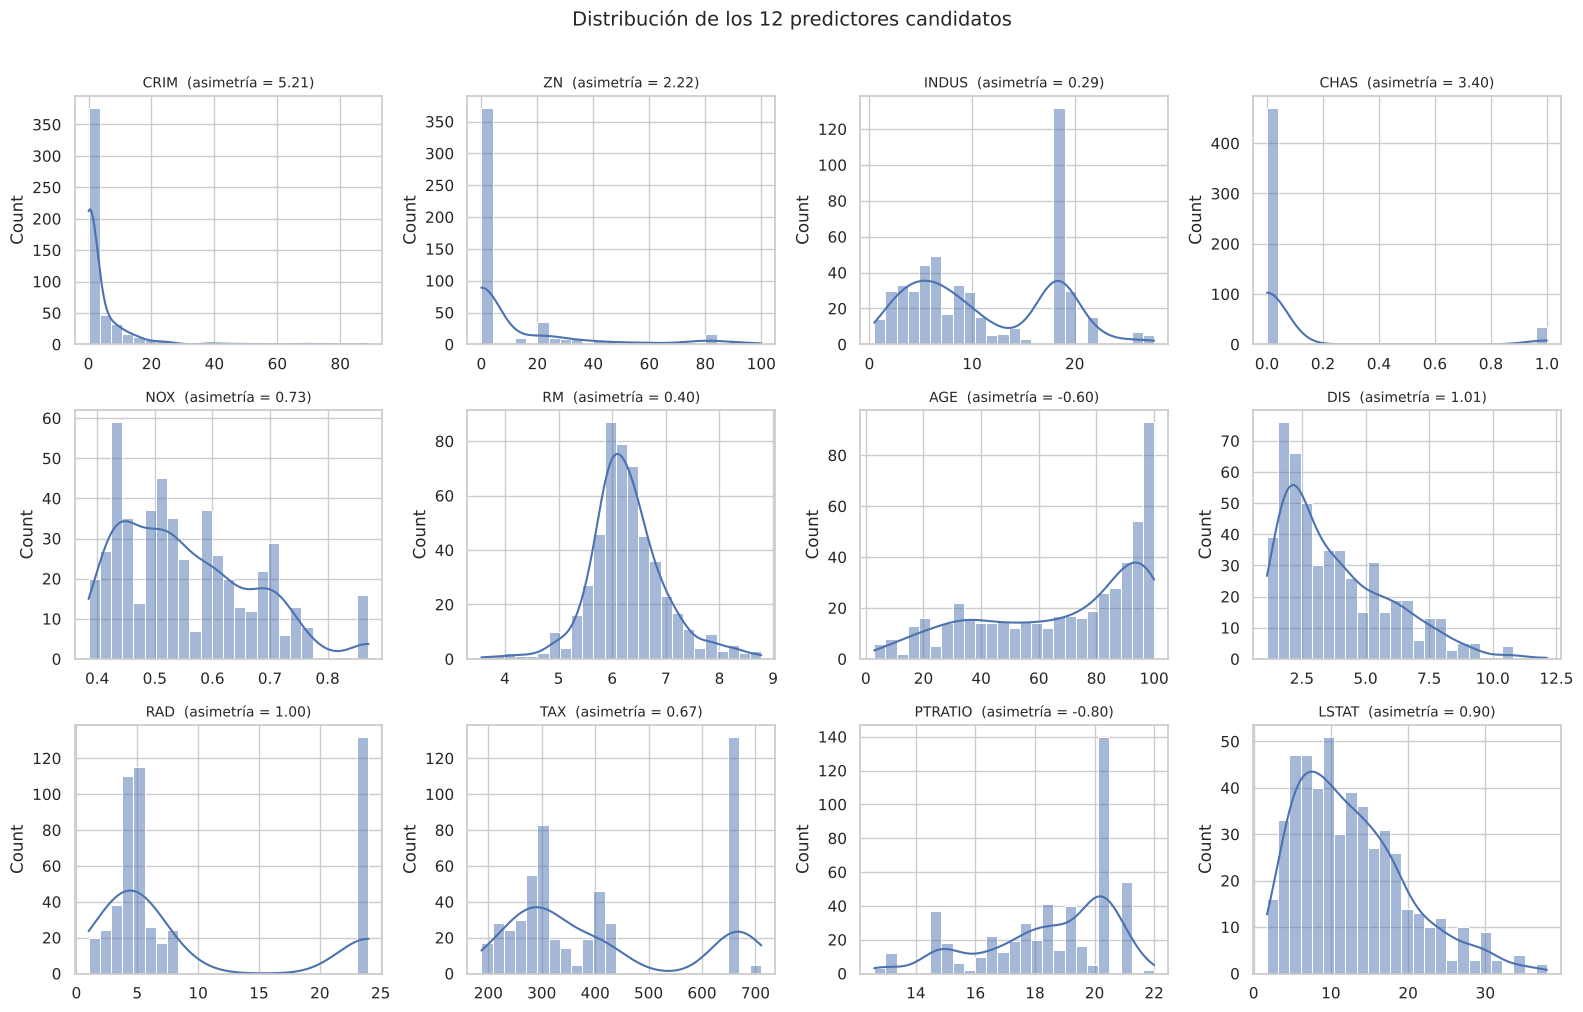

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, var in zip(axes.flat, PREDICTORES):
    sns.histplot(df[var], kde=True, ax=ax, bins=25)
    ax.set_title(f"{var}  (asimetría = {stats.skew(df[var]):.2f})", fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Distribución de los 12 predictores candidatos", fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

## 3.4 Relación de cada predictor con la respuesta

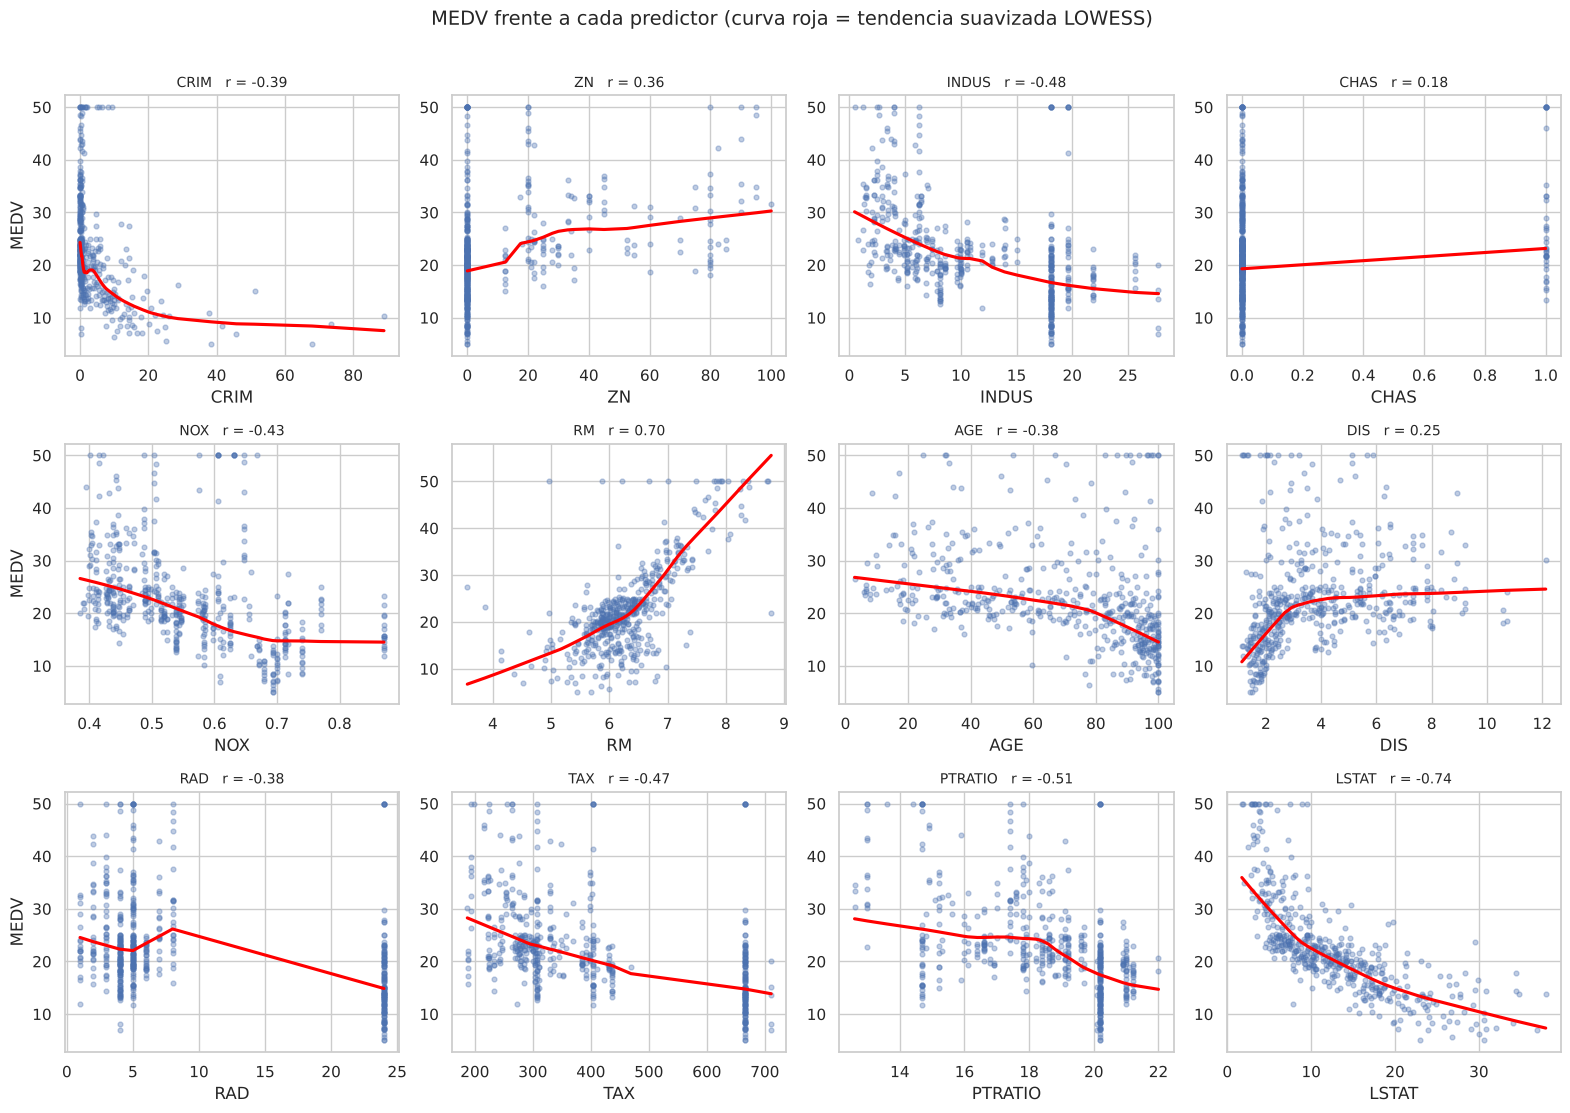

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, var in zip(axes.flat, PREDICTORES):
    sns.regplot(x=df[var], y=df[RESPUESTA], ax=ax, lowess=True,
                scatter_kws={"alpha": .35, "s": 12}, line_kws={"color": "red"})
    r = df[var].corr(df[RESPUESTA])
    ax.set_title(f"{var}   r = {r:.2f}", fontsize=10)
    ax.set_ylabel("MEDV" if var in PREDICTORES[::4] else "")
plt.suptitle("MEDV frente a cada predictor (curva roja = tendencia suavizada LOWESS)", fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

**Lo que vemos:**
- `RM` (+) y `LSTAT` (–) son los predictores más fuertes. La relación con `LSTAT` es **curva**.
- `CRIM`, `DIS`, `NOX` también muestran relaciones no lineales.
- Varias curvas (LOWESS) se ven más rectas si la respuesta está en escala logarítmica. Lo comprobaremos en la Parte 5.

## 3.5 Correlaciones entre predictores (alerta de colinealidad)

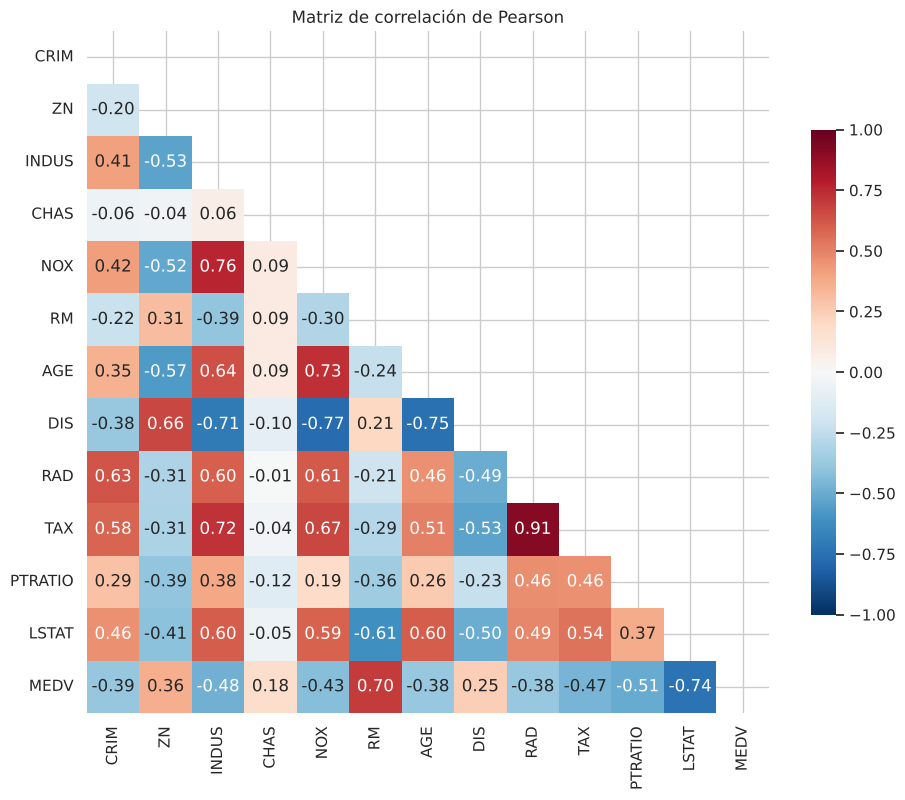

In [11]:
corr = df.corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .7})
plt.title("Matriz de correlación de Pearson")
plt.show()

In [12]:
# Pares de predictores con |r| > 0.7
pares = (corr.loc[PREDICTORES, PREDICTORES]
         .where(np.triu(np.ones((len(PREDICTORES),) * 2), k=1).astype(bool))
         .stack().reset_index())
pares.columns = ["variable_1", "variable_2", "r"]
pares[pares.r.abs() > 0.7].sort_values("r", key=abs, ascending=False)

,variable_1,variable_2,r
105,RAD,TAX,0.9102
55,NOX,DIS,-0.7692
28,INDUS,NOX,0.7637
79,AGE,DIS,-0.7479
54,NOX,AGE,0.7315
33,INDUS,TAX,0.7208
31,INDUS,DIS,-0.7080


**Alerta:** `RAD` y `TAX` tienen $r = 0.91$: prácticamente **dicen lo mismo**. También `NOX`–`DIS`, `INDUS`–`NOX`, `AGE`–`DIS`. Cuando dos predictores son redundantes, los métodos de selección tienden a quedarse con **uno** de ellos, y cuál de los dos puede depender de detalles de la muestra.

### ✍️ Síntesis del EDA (para el informe)
1. Sin faltantes ni duplicados; respuesta asimétrica y censurada en 50.
2. Predictores fuertes: `LSTAT`, `RM`, `PTRATIO`. Relaciones curvas en varios casos.
3. Colinealidad fuerte entre `RAD`/`TAX` y en el bloque `NOX`/`DIS`/`INDUS`/`AGE`.

---
# PARTE 4. División entrenamiento / prueba

> 🔑 **Regla de oro:** la selección de variables **es parte del entrenamiento**. Si seleccionamos con todos los datos y luego evaluamos con esos mismos datos, el error estimado será optimista (*fuga de información*). Por eso separamos **antes** de seleccionar.

In [13]:
train, test = train_test_split(df, test_size=0.20, random_state=SEMILLA)
print(f"Entrenamiento: {train.shape[0]} filas   |   Prueba: {test.shape[0]} filas")

X_train, X_test = train[PREDICTORES], test[PREDICTORES]

Entrenamiento: 404 filas   |   Prueba: 102 filas


---
# PARTE 5. El modelo completo y su diagnóstico

Primero ajustamos el modelo con **todos** los candidatos. Es nuestro punto de referencia y el punto de partida de la eliminación hacia atrás.

In [14]:
formula_completa = "MEDV ~ " + " + ".join(PREDICTORES)
modelo_completo = smf.ols(formula_completa, data=train).fit()
print(modelo_completo.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.740
Model:                            OLS   Adj. R-squared:                  0.732
Method:                 Least Squares   F-statistic:                     92.80
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          2.20e-106
Time:                        17:02:37   Log-Likelihood:                -1192.1
No. Observations:                 404   AIC:                             2410.
Df Residuals:                     391   BIC:                             2462.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     42.7027      5.330      8.012      0.0

### ¿Cómo leer esta salida?
- **`R-squared` / `Adj. R-squared`**: proporción de la variabilidad de `MEDV` explicada.
- **`F-statistic` y `Prob (F-statistic)`**: prueba global $H_0:\beta_1=\cdots=\beta_k=0$. Si $p<0.05$, al menos un predictor sirve.
- **`coef`**: cambio esperado en `MEDV` por un aumento de una unidad en el predictor, **manteniendo constantes los demás**.
- **`P>|t|`**: prueba individual $H_0:\beta_j=0$ *dado que las demás variables están en el modelo*.

Ya aparecen candidatos a salir: `INDUS` y `AGE` tienen $p$-valores muy grandes.

## 5.1 Multicolinealidad: Factor de Inflación de la Varianza (VIF)

$$VIF_j = \frac{1}{1-R_j^2},$$

donde $R^2_j$ es el $R^2$ de regresar $X_j$ sobre los otros predictores. Regla práctica: $VIF>5$ merece atención, $VIF>10$ es problemático.

In [15]:
def tabla_vif(X):
    Xc = sm.add_constant(X)
    return (pd.DataFrame({"variable": X.columns,
                          "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]})
            .sort_values("VIF", ascending=False).reset_index(drop=True))

tabla_vif(X_train)

,variable,VIF
0,TAX,9.2199
1,RAD,7.9854
2,NOX,4.1770
3,DIS,3.8557
4,INDUS,3.7839
5,AGE,3.2357
6,LSTAT,2.9843
7,CRIM,2.3258
8,ZN,2.2195
9,RM,1.8883


`TAX` y `RAD` tienen los VIF más altos, como anticipaba la matriz de correlación.

## 5.2 Diagnóstico gráfico de los residuos

Antes de seleccionar variables hay que verificar que **la forma del modelo es razonable**. Si el modelo completo está mal especificado, cualquier selección hecha sobre él también lo estará.

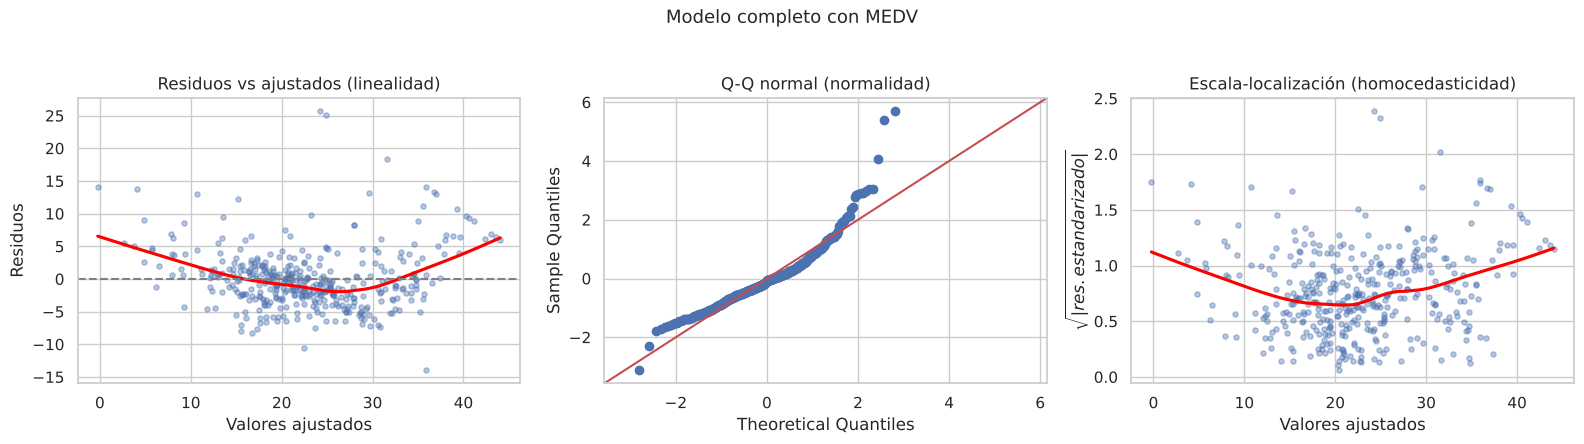

Breusch-Pagan (H0: varianza constante): p = 3.232e-05
Shapiro-Wilk  (H0: normalidad):         p = 1.404e-14


In [16]:
def graficos_diagnostico(modelo, titulo=""):
    ajustados, residuos = modelo.fittedvalues, modelo.resid
    res_est = modelo.get_influence().resid_studentized_internal
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

    sns.regplot(x=ajustados, y=residuos, lowess=True, ax=axes[0],
                scatter_kws={"alpha": .4, "s": 14}, line_kws={"color": "red"})
    axes[0].axhline(0, ls="--", c="gray"); axes[0].set(xlabel="Valores ajustados", ylabel="Residuos",
                                                      title="Residuos vs ajustados (linealidad)")
    sm.qqplot(res_est, line="45", ax=axes[1]); axes[1].set_title("Q-Q normal (normalidad)")

    sns.regplot(x=ajustados, y=np.sqrt(np.abs(res_est)), lowess=True, ax=axes[2],
                scatter_kws={"alpha": .4, "s": 14}, line_kws={"color": "red"})
    axes[2].set(xlabel="Valores ajustados", ylabel=r"$\sqrt{|res. estandarizado|}$",
                title="Escala-localización (homocedasticidad)")
    plt.suptitle(titulo, fontsize=13, y=1.03); plt.tight_layout(); plt.show()

    bp = het_breuschpagan(residuos, modelo.model.exog)
    sw = stats.shapiro(residuos)
    print(f"Breusch-Pagan (H0: varianza constante): p = {bp[1]:.4g}")
    print(f"Shapiro-Wilk  (H0: normalidad):         p = {sw.pvalue:.4g}")

graficos_diagnostico(modelo_completo, "Modelo completo con MEDV")

**Diagnóstico:**
- El gráfico de residuos vs ajustados muestra una **curva en U** → la relación no es del todo lineal.
- El Q-Q muestra **colas pesadas** a la derecha (en parte por los valores topados en 50).
- La dispersión **no es constante**.

### Remedio: transformar la respuesta

Con respuestas positivas y asimétricas a la derecha, el logaritmo suele linealizar y estabilizar la varianza. Probemos $\log(\text{MEDV})$.

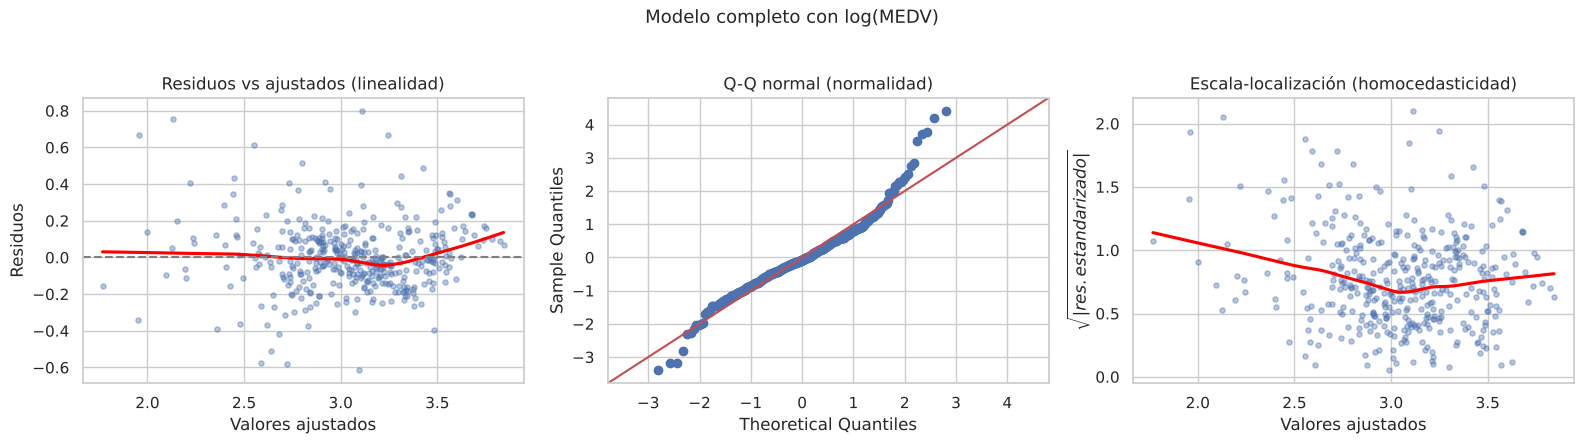

Breusch-Pagan (H0: varianza constante): p = 5.959e-06
Shapiro-Wilk  (H0: normalidad):         p = 1.152e-09

R² ajustado:  MEDV = 0.732   |   log(MEDV) = 0.783


In [17]:
train = train.assign(logMEDV=np.log(train.MEDV))
test = test.assign(logMEDV=np.log(test.MEDV))

modelo_completo_log = smf.ols("logMEDV ~ " + " + ".join(PREDICTORES), data=train).fit()
graficos_diagnostico(modelo_completo_log, "Modelo completo con log(MEDV)")
print(f"\nR² ajustado:  MEDV = {modelo_completo.rsquared_adj:.3f}   |   log(MEDV) = {modelo_completo_log.rsquared_adj:.3f}")

**Decisión:** con $\log(\text{MEDV})$ la curvatura casi desaparece, el Q-Q mejora y el $R^2_{aj}$ sube. Aún queda algo de heterocedasticidad (Breusch-Pagan sigue siendo significativo con $n$ grande): lo atenderemos al final con **errores estándar robustos**.

> 📌 **A partir de aquí, la respuesta es `logMEDV`.** Interpretación: si $\beta_j$ es pequeño, $100\cdot\beta_j$ ≈ **cambio porcentual** en `MEDV` por una unidad más de $X_j$ (exactamente: $100(e^{\beta_j}-1)\%$).

In [18]:
Y = "logMEDV"
y_train, y_test = train[Y], test[Y]

---
# PARTE 6. La herramienta clave: la prueba $F$ parcial

Todos los métodos clásicos (*forward*, *backward*, *stepwise*) comparan **modelos anidados**: uno reducido (R) y otro ampliado (A) que tiene las mismas variables más alguna(s) adicional(es).

$$
F = \frac{\left(SC_{Res}^{(R)} - SC_{Res}^{(A)}\right) / q}{SC_{Res}^{(A)} / (n - p_A)} \;\sim\; F_{q,\;n-p_A}
\qquad\text{bajo } H_0: \text{las } q \text{ variables añadidas tienen } \beta=0.
$$

Cuando se añade **una sola** variable ($q=1$), se cumple que $F = t^2$: el $p$-valor de la prueba $F$ parcial es **idéntico** al $p$-valor de la prueba $t$ del coeficiente nuevo. Por eso los algoritmos suelen usar directamente el $p$-valor de `summary()`.

Comprobémoslo:

In [19]:
m_R = smf.ols("logMEDV ~ LSTAT", data=train).fit()
m_A = smf.ols("logMEDV ~ LSTAT + RM", data=train).fit()

print(sm.stats.anova_lm(m_R, m_A))      # prueba F parcial (modelos anidados)
print(f"\nt de RM en el modelo ampliado = {m_A.tvalues['RM']:.4f}   ->  t² = {m_A.tvalues['RM']**2:.4f}")
print(f"p-valor de la prueba t        = {m_A.pvalues['RM']:.3e}")

   df_resid      ssr  df_diff  ss_diff        F      Pr(>F)
0     402.0  21.6354      0.0      NaN      NaN         NaN
1     401.0  19.2988      1.0   2.3366  48.5509  1.3279e-11

t de RM en el modelo ampliado = 6.9678   ->  t² = 48.5509
p-valor de la prueba t        = 1.328e-11


✔ El estadístico $F$ coincide con $t^2$ y los $p$-valores son los mismos.

> 🔗 **Conexión con ANOVA:** esta prueba $F$ es exactamente la misma lógica del análisis de varianza: comparamos cuánta variabilidad **adicional** explica un término frente a la variabilidad residual. Lo veremos en el cuadernillo de ANOVA.

---
# PARTE 7. Selección hacia adelante (*Forward Selection*) — paso a paso

### La idea
Empezamos con el **modelo nulo** (sólo intercepto) y vamos **agregando** variables, **una por vez**, siempre la que más mejora el modelo.

### El algoritmo
1. Modelo actual: $Y = \beta_0$.
2. Para **cada** variable que todavía no está, ajustar el modelo actual **+ esa variable** y calcular su $p$-valor (o AIC).
3. Elegir la variable con **menor $p$-valor** (o menor AIC).
4. Si ese $p$-valor $< \alpha_{entrada}$ (o el AIC baja) → **entra** y volvemos al paso 2. Si no → **paramos**.

> ⚠️ Una vez que una variable entra, **nunca sale**.

### Paso 1, hecho "a mano"

Ajustamos los 12 modelos de **una sola variable**:

In [20]:
def evaluar_candidatos(datos, y, seleccionadas, candidatas):
    '''Ajusta (seleccionadas + c) para cada candidata c y reporta p-valor, AIC y R² ajustado.'''
    filas = []
    for c in candidatas:
        f = f"{y} ~ " + " + ".join(seleccionadas + [c])
        m = smf.ols(f, data=datos).fit()
        filas.append({"variable_candidata": c, "p_valor": m.pvalues[c],
                      "AIC": m.aic, "R2_ajustado": m.rsquared_adj})
    return pd.DataFrame(filas).sort_values("p_valor").reset_index(drop=True)

paso1 = evaluar_candidatos(train, Y, [], PREDICTORES)
paso1

,variable_candidata,p_valor,AIC,R2_ajustado
0,LSTAT,9.7978e-95,-32.0394,0.6534
1,RM,1.3062e-49,176.3629,0.4193
2,CRIM,5.8863e-36,239.2922,0.3215
3,TAX,1.5767e-32,255.0706,0.2945
4,INDUS,1.4681e-31,259.5289,0.2866
5,NOX,1.2967e-27,277.6729,0.2539
6,PTRATIO,1.0351e-26,281.8180,0.2462
7,RAD,9.2132e-23,299.9489,0.2116
8,AGE,3.7555e-22,302.7477,0.2061
9,ZN,3.9263e-15,334.8639,0.1404


**Gana `LSTAT`**: tiene el menor $p$-valor (y el menor AIC). Entra al modelo.

### Paso 2
Ahora probamos `LSTAT` + cada una de las 11 variables restantes:

In [21]:
paso2 = evaluar_candidatos(train, Y, ["LSTAT"], [v for v in PREDICTORES if v != "LSTAT"])
paso2

,variable_candidata,p_valor,AIC,R2_ajustado
0,PTRATIO,3.0832e-14,-88.2232,0.6991
1,RM,1.3279e-11,-76.2116,0.6900
2,CRIM,9.5559e-07,-54.2647,0.6727
3,TAX,2.8905e-05,-47.6806,0.6673
4,CHAS,4.9473e-04,-42.2808,0.6629
5,DIS,1.2459e-03,-40.5514,0.6614
6,RAD,1.6591e-02,-35.8286,0.6574
7,INDUS,5.6739e-02,-33.7013,0.6556
8,ZN,1.6060e-01,-32.0252,0.6542
9,AGE,1.6092e-01,-32.0221,0.6542


**Gana `PTRATIO`.** Observe que el ranking **cambió** respecto al paso 1: `RM` era la segunda mejor sola, pero **dado** que `LSTAT` ya está, `PTRATIO` aporta más información *nueva*. Esa es la esencia de la regresión múltiple: lo que importa es el aporte **parcial**.

### El algoritmo completo

Automatizamos el procedimiento. La función guarda un **historial** de cada paso para que podamos ver qué ocurrió.

In [22]:
def seleccion_forward(datos, y, candidatas, criterio="p", alfa_entrada=0.05, verbose=True):
    '''
    Selección hacia adelante.
    criterio = "p"   -> entra la variable con menor p-valor si p < alfa_entrada
    criterio = "aic" -> entra la variable que más reduce el AIC; para si ninguna lo reduce
    criterio = "bic" -> igual que AIC pero con BIC
    '''
    seleccionadas, restantes, historial = [], list(candidatas), []
    m_actual = smf.ols(f"{y} ~ 1", data=datos).fit()
    while restantes:
        tabla = evaluar_candidatos(datos, y, seleccionadas, restantes)
        if criterio == "p":
            mejor = tabla.iloc[0]
            entra = mejor.p_valor < alfa_entrada
        else:
            ic = {}
            for c in restantes:
                m = smf.ols(f"{y} ~ " + " + ".join(seleccionadas + [c]), data=datos).fit()
                ic[c] = m.aic if criterio == "aic" else m.bic
            c_mejor = min(ic, key=ic.get)
            mejor = tabla.set_index("variable_candidata").loc[c_mejor].copy()
            mejor["variable_candidata"] = c_mejor
            actual = m_actual.aic if criterio == "aic" else m_actual.bic
            entra = ic[c_mejor] < actual
        if not entra:
            if verbose:
                print(f"  ✋ Paramos: la mejor candidata ({mejor.variable_candidata}) no cumple el criterio.")
            break
        seleccionadas.append(mejor.variable_candidata)
        restantes.remove(mejor.variable_candidata)
        m_actual = smf.ols(f"{y} ~ " + " + ".join(seleccionadas), data=datos).fit()
        historial.append({"paso": len(seleccionadas), "entra": mejor.variable_candidata,
                          "p_valor": mejor.p_valor, "AIC": m_actual.aic, "BIC": m_actual.bic,
                          "R2_ajustado": m_actual.rsquared_adj})
        if verbose:
            print(f"Paso {len(seleccionadas):>2}: entra {mejor.variable_candidata:<8}  "
                  f"p = {mejor.p_valor:.2e}   AIC = {m_actual.aic:8.2f}   R²aj = {m_actual.rsquared_adj:.4f}")
    return seleccionadas, pd.DataFrame(historial)

print("=== FORWARD con criterio p-valor (α = 0.05) ===")
vars_fwd_p, hist_fwd = seleccion_forward(train, Y, PREDICTORES, criterio="p", alfa_entrada=0.05)
print("\nVariables seleccionadas:", vars_fwd_p)

=== FORWARD con criterio p-valor (α = 0.05) ===


Paso  1: entra LSTAT     p = 9.80e-95   AIC =   -32.04   R²aj = 0.6534


Paso  2: entra PTRATIO   p = 3.08e-14   AIC =   -88.22   R²aj = 0.6991
Paso  3: entra RM        p = 2.60e-09   AIC =  -122.09   R²aj = 0.7240


Paso  4: entra CRIM      p = 6.95e-07   AIC =  -145.06   R²aj = 0.7399


Paso  5: entra DIS       p = 9.02e-05   AIC =  -158.64   R²aj = 0.7491


Paso  6: entra NOX       p = 4.79e-07   AIC =  -182.46   R²aj = 0.7640


Paso  7: entra RAD       p = 1.56e-04   AIC =  -195.07   R²aj = 0.7718
Paso  8: entra TAX       p = 6.97e-05   AIC =  -209.27   R²aj = 0.7802


Paso  9: entra ZN        p = 1.64e-02   AIC =  -213.18   R²aj = 0.7829


  ✋ Paramos: la mejor candidata (CHAS) no cumple el criterio.

Variables seleccionadas: ['LSTAT', 'PTRATIO', 'RM', 'CRIM', 'DIS', 'NOX', 'RAD', 'TAX', 'ZN']


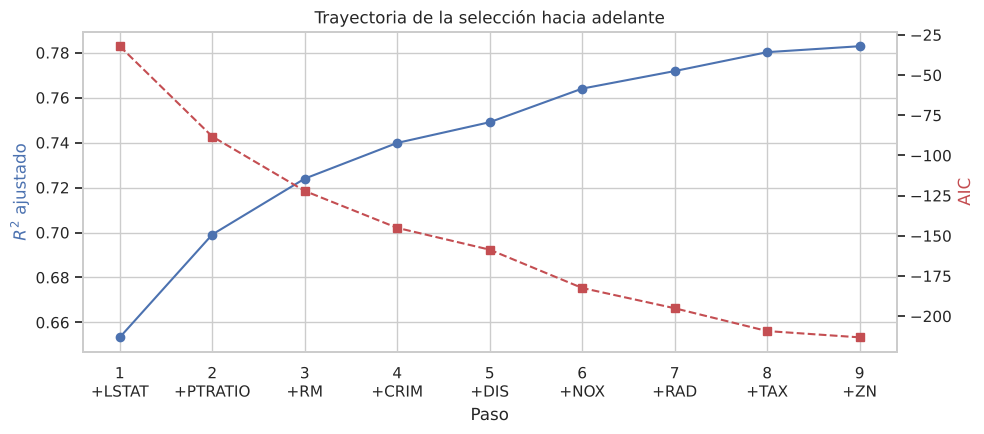

In [23]:
# Visualicemos la trayectoria: cómo mejora el modelo con cada variable que entra
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(hist_fwd.paso, hist_fwd.R2_ajustado, "o-", color="C0", label="$R^2$ ajustado")
ax1.set_ylabel("$R^2$ ajustado", color="C0"); ax1.set_xlabel("Paso")
ax1.set_xticks(hist_fwd.paso)
ax1.set_xticklabels([f"{p}\n+{v}" for p, v in zip(hist_fwd.paso, hist_fwd.entra)])
ax2 = ax1.twinx()
ax2.plot(hist_fwd.paso, hist_fwd.AIC, "s--", color="C3", label="AIC")
ax2.set_ylabel("AIC", color="C3"); ax2.grid(False)
plt.title("Trayectoria de la selección hacia adelante"); plt.tight_layout(); plt.show()

**Lectura del gráfico:** las primeras variables (`LSTAT`, `PTRATIO`, `RM`) producen grandes saltos; las últimas aportan mejoras cada vez más pequeñas. Ese "codo" es típico: **rendimientos decrecientes**.

✏️ **Experimente:** cambie `alfa_entrada` a `0.01` o `0.15` y observe cuántas variables entran. ¿Qué relación hay entre $\alpha$ y el tamaño del modelo?

### *Forward* con AIC y con BIC

In [24]:
print("=== FORWARD con AIC ===")
vars_fwd_aic, _ = seleccion_forward(train, Y, PREDICTORES, criterio="aic")
print("\n=== FORWARD con BIC ===")
vars_fwd_bic, _ = seleccion_forward(train, Y, PREDICTORES, criterio="bic")

=== FORWARD con AIC ===


Paso  1: entra LSTAT     p = 9.80e-95   AIC =   -32.04   R²aj = 0.6534


Paso  2: entra PTRATIO   p = 3.08e-14   AIC =   -88.22   R²aj = 0.6991


Paso  3: entra RM        p = 2.60e-09   AIC =  -122.09   R²aj = 0.7240


Paso  4: entra CRIM      p = 6.95e-07   AIC =  -145.06   R²aj = 0.7399


...

Paso  5: entra DIS       p = 9.02e-05   AIC =  -158.64   R²aj = 0.7491


Paso  6: entra NOX       p = 4.79e-07   AIC =  -182.46   R²aj = 0.7640


Paso  7: entra RAD       p = 1.56e-04   AIC =  -195.07   R²aj = 0.7718


Paso  8: entra TAX       p = 6.97e-05   AIC =  -209.27   R²aj = 0.7802


  ✋ Paramos: la mejor candidata (ZN) no cumple el criterio.


Observe que **el criterio cambia la respuesta**: AIC (penalización suave, $2p$) tiende a dejar más variables; BIC (penalización $p\ln n$) es más exigente. Ninguno es "el correcto": AIC apunta a **predecir bien**, BIC a **identificar el modelo verdadero** si está entre los candidatos.

---
# PARTE 8. Eliminación hacia atrás (*Backward Elimination*)

### La idea
Hacemos lo contrario: empezamos con el **modelo completo** y vamos **quitando** variables.

### El algoritmo
1. Ajustar el modelo con todas las variables.
2. Identificar la variable con **mayor $p$-valor**.
3. Si ese $p$-valor $> \alpha_{salida}$ → **sale**, reajustar y volver al paso 2. Si no → **paramos**.

> ⚠️ Una vez que una variable sale, **nunca vuelve**. Además, no se puede usar si hay más variables que observaciones ($k > n$).

In [25]:
def seleccion_backward(datos, y, candidatas, alfa_salida=0.05, verbose=True):
    seleccionadas, historial = list(candidatas), []
    while seleccionadas:
        m = smf.ols(f"{y} ~ " + " + ".join(seleccionadas), data=datos).fit()
        pvals = m.pvalues.drop("Intercept")
        peor, p_peor = pvals.idxmax(), pvals.max()
        if p_peor <= alfa_salida:
            if verbose:
                print(f"  ✋ Paramos: todas las variables tienen p ≤ {alfa_salida}. (mayor p = {p_peor:.3g}, {peor})")
            break
        seleccionadas.remove(peor)
        m_nuevo = smf.ols(f"{y} ~ " + (" + ".join(seleccionadas) if seleccionadas else "1"), data=datos).fit()
        historial.append({"paso": len(historial) + 1, "sale": peor, "p_valor": p_peor,
                          "AIC": m_nuevo.aic, "R2_ajustado": m_nuevo.rsquared_adj})
        if verbose:
            print(f"Paso {len(historial):>2}: sale {peor:<8}  p = {p_peor:.3f}   "
                  f"AIC nuevo = {m_nuevo.aic:8.2f}   R²aj = {m_nuevo.rsquared_adj:.4f}")
    return seleccionadas, pd.DataFrame(historial)

print("=== BACKWARD con criterio p-valor (α = 0.05) ===")
vars_bwd, hist_bwd = seleccion_backward(train, Y, PREDICTORES, alfa_salida=0.05)
print("\nVariables seleccionadas:", vars_bwd)

=== BACKWARD con criterio p-valor (α = 0.05) ===
Paso  1: sale AGE       p = 0.963   AIC nuevo =  -212.89   R²aj = 0.7838
Paso  2: sale INDUS     p = 0.545   AIC nuevo =  -214.51   R²aj = 0.7841
Paso  3: sale CHAS      p = 0.072   AIC nuevo =  -213.18   R²aj = 0.7829


  ✋ Paramos: todas las variables tienen p ≤ 0.05. (mayor p = 0.0164, ZN)

Variables seleccionadas: ['CRIM', 'ZN', 'NOX', 'RM', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT']


**Observe:** al quitar una variable, los $p$-valores de las demás **cambian**. Por eso se elimina **de una en una** y se reajusta: nunca se borran todas las no significativas al mismo tiempo.

---
# PARTE 9. Selección por pasos (*Stepwise*, bidireccional)

### La idea
Combina las dos anteriores: en cada paso **intenta añadir** la mejor variable (como *forward*) y luego **revisa** si alguna de las que ya están perdió importancia y debe **salir** (como *backward*).

¿Por qué podría salir una variable que ya entró? Porque al llegar otra variable correlacionada, la primera puede volverse **redundante**.

> 📏 Se exige $\alpha_{entrada} \le \alpha_{salida}$ para evitar que una variable entre y salga indefinidamente (ciclos). Valores típicos: entrar con 0.05, salir con 0.10.

In [26]:
def seleccion_stepwise(datos, y, candidatas, alfa_entrada=0.05, alfa_salida=0.10, max_pasos=50, verbose=True):
    assert alfa_entrada <= alfa_salida, "Debe cumplirse alfa_entrada <= alfa_salida"
    seleccionadas = []
    for paso in range(1, max_pasos + 1):
        cambio = False
        # --- Paso hacia adelante ---
        restantes = [c for c in candidatas if c not in seleccionadas]
        if restantes:
            tabla = evaluar_candidatos(datos, y, seleccionadas, restantes)
            if tabla.p_valor.iloc[0] < alfa_entrada:
                nueva = tabla.variable_candidata.iloc[0]
                seleccionadas.append(nueva); cambio = True
                if verbose: print(f"Paso {paso:>2}: ➕ entra {nueva:<8} (p = {tabla.p_valor.iloc[0]:.2e})")
        # --- Paso hacia atrás ---
        if seleccionadas:
            m = smf.ols(f"{y} ~ " + " + ".join(seleccionadas), data=datos).fit()
            pvals = m.pvalues.drop("Intercept")
            if pvals.max() > alfa_salida:
                sale = pvals.idxmax()
                seleccionadas.remove(sale); cambio = True
                if verbose: print(f"         ➖ sale  {sale:<8} (p = {pvals.max():.3f})")
        if not cambio:
            if verbose: print("  ✋ Ninguna variable entra ni sale: fin.")
            break
    return seleccionadas

print("=== STEPWISE (entra α=0.05, sale α=0.10) ===")
vars_step = seleccion_stepwise(train, Y, PREDICTORES)
print("\nVariables seleccionadas:", vars_step)

=== STEPWISE (entra α=0.05, sale α=0.10) ===
Paso  1: ➕ entra LSTAT    (p = 9.80e-95)


Paso  2: ➕ entra PTRATIO  (p = 3.08e-14)
Paso  3: ➕ entra RM       (p = 2.60e-09)


Paso  4: ➕ entra CRIM     (p = 6.95e-07)


Paso  5: ➕ entra DIS      (p = 9.02e-05)
Paso  6: ➕ entra NOX      (p = 4.79e-07)


Paso  7: ➕ entra RAD      (p = 1.56e-04)


Paso  8: ➕ entra TAX      (p = 6.97e-05)
Paso  9: ➕ entra ZN       (p = 1.64e-02)


  ✋ Ninguna variable entra ni sale: fin.

Variables seleccionadas: ['LSTAT', 'PTRATIO', 'RM', 'CRIM', 'DIS', 'NOX', 'RAD', 'TAX', 'ZN']


En estos datos ninguna variable tuvo que salir después de entrar, así que *stepwise* coincide con *forward*. Esto no siempre ocurre: con predictores muy correlacionados es común ver salidas.

---
# PARTE 10. La referencia: búsqueda exhaustiva (*Best Subset*)

Con 12 predictores existen $2^{12} = 4096$ modelos posibles. Hoy un computador los ajusta todos en segundos. Esto nos permite **verificar** si los métodos secuenciales encontraron el mejor modelo, o se quedaron en uno "bueno pero no óptimo".

> Los métodos *forward/backward/stepwise* son **voraces** (*greedy*): toman la mejor decisión **local** en cada paso, lo que **no garantiza** el mejor modelo **global**. Con 40 predictores ya habría $\approx 10^{12}$ modelos y la búsqueda exhaustiva sería inviable: por eso existen los métodos secuenciales.

In [27]:
def best_subset(datos, y, candidatas):
    yv = datos[y].values
    n = len(yv)
    sct = ((yv - yv.mean()) ** 2).sum()
    filas = []
    for k in range(0, len(candidatas) + 1):
        for comb in itertools.combinations(candidatas, k):
            X = np.column_stack([np.ones(n)] + [datos[c].values for c in comb])
            beta, *_ = np.linalg.lstsq(X, yv, rcond=None)
            scr = ((yv - X @ beta) ** 2).sum()
            p = k + 1
            llf = -n / 2 * (np.log(2 * np.pi) + np.log(scr / n) + 1)   # log-verosimilitud gaussiana
            filas.append({"k": k, "variables": comb, "SCRes": scr,
                          "R2_ajustado": 1 - (scr / (n - p)) / (sct / (n - 1)),
                          "AIC": -2 * llf + 2 * p, "BIC": -2 * llf + np.log(n) * p})
    return pd.DataFrame(filas)

todos = best_subset(train, Y, PREDICTORES)
print(f"Modelos ajustados: {len(todos)}")

Modelos ajustados: 4096


In [28]:
mejores_por_k = todos.loc[todos.groupby("k").SCRes.idxmin()].reset_index(drop=True)
mejores_por_k["variables"] = mejores_por_k.variables.apply(lambda t: ", ".join(t) if t else "(sólo intercepto)")
mejores_por_k[["k", "variables", "R2_ajustado", "AIC", "BIC"]]

,k,variables,R2_ajustado,AIC,BIC
0,0,(sólo intercepto),2.2204e-16,394.9838,398.9852
1,1,LSTAT,6.5335e-01,-32.0394,-24.0365
2,2,"PTRATIO, LSTAT",6.9910e-01,-88.2232,-76.2189
3,3,"RM, PTRATIO, LSTAT",7.2397e-01,-122.0866,-106.0810
4,4,"CRIM, RM, PTRATIO, LSTAT",7.3987e-01,-145.0564,-125.0493
5,5,"CRIM, RM, DIS, PTRATIO, LSTAT",7.4908e-01,-158.6375,-134.6291
6,6,"CRIM, NOX, RM, DIS, PTRATIO, LSTAT",7.6402e-01,-182.4637,-154.4538
7,7,"CRIM, NOX, RM, DIS, RAD, PTRATIO, LSTAT",7.7183e-01,-195.0724,-163.0611
8,8,"CRIM, NOX, RM, DIS, RAD, TAX, PTRATIO, LSTAT",7.8024e-01,-209.2719,-173.2592
9,9,"CRIM, ZN, NOX, RM, DIS, RAD, TAX, PTRATIO, LSTAT",7.8289e-01,-213.1836,-173.1694


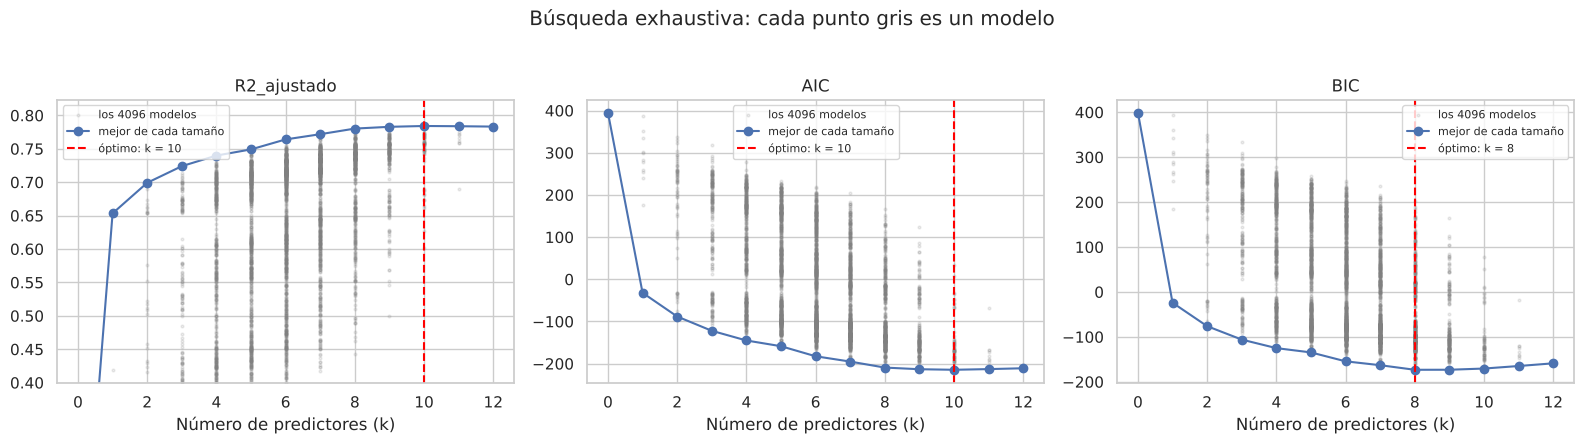

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, crit, mejor_fn in zip(axes, ["R2_ajustado", "AIC", "BIC"], [np.argmax, np.argmin, np.argmin]):
    ax.scatter(todos.k, todos[crit], s=4, alpha=.15, color="gray", label="los 4096 modelos")
    ax.plot(mejores_por_k.k, mejores_por_k[crit], "o-", color="C0", label="mejor de cada tamaño")
    kopt = mejores_por_k.k[mejor_fn(mejores_por_k[crit].values)]
    ax.axvline(kopt, color="red", ls="--", label=f"óptimo: k = {kopt}")
    ax.set(xlabel="Número de predictores (k)", title=crit); ax.legend(fontsize=8)
axes[0].set_ylim(0.4, None)
plt.suptitle("Búsqueda exhaustiva: cada punto gris es un modelo", y=1.03); plt.tight_layout(); plt.show()

In [30]:
mejor_aic = list(todos.loc[todos.AIC.idxmin(), "variables"])
mejor_bic = list(todos.loc[todos.BIC.idxmin(), "variables"])
mejor_r2a = list(todos.loc[todos.R2_ajustado.idxmax(), "variables"])
print("Mejor por AIC :", mejor_aic)
print("Mejor por BIC :", mejor_bic)
print("Mejor por R²aj:", mejor_r2a)

Mejor por AIC : ['CRIM', 'ZN', 'CHAS', 'NOX', 'RM', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT']
Mejor por BIC : ['CRIM', 'NOX', 'RM', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT']
Mejor por R²aj: ['CRIM', 'ZN', 'CHAS', 'NOX', 'RM', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT']


**Lectura:** las tres curvas son muy **planas** alrededor del óptimo: modelos de 8, 9 o 10 variables son casi equivalentes. Cuando varios modelos están "empatados", el criterio estadístico no basta y entran a decidir la **simplicidad** y el **conocimiento del tema**.

---
# PARTE 11. Selección con validación cruzada (enfoque predictivo, `scikit-learn`)

Los métodos anteriores usan criterios **dentro de la muestra**. Otra opción es elegir las variables según el **error de predicción fuera de muestra**, estimado con validación cruzada ($K$-fold).

`SequentialFeatureSelector` de `scikit-learn` implementa *forward* y *backward* con ese criterio. Con `n_features_to_select="auto"` y `tol`, se detiene cuando la mejora en el puntaje es menor que `tol`.

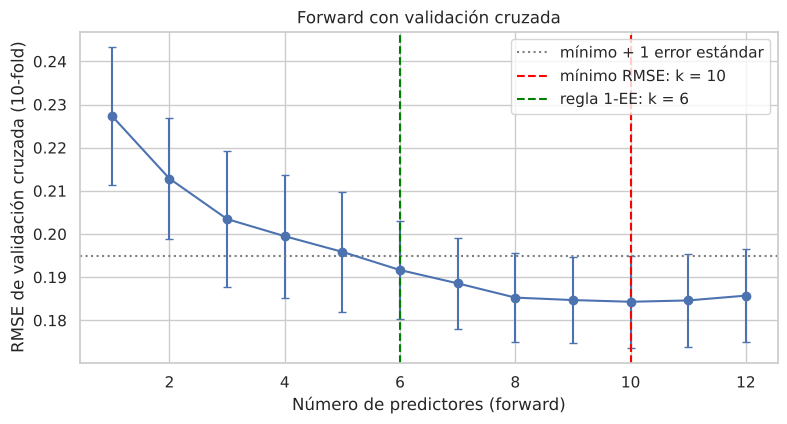

Variables con mínimo RMSE   : ['CRIM', 'ZN', 'CHAS', 'NOX', 'RM', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT']
Variables con la regla 1-EE : ['CRIM', 'NOX', 'RM', 'DIS', 'PTRATIO', 'LSTAT']


In [31]:
kf = KFold(n_splits=10, shuffle=True, random_state=SEMILLA)

resultados_cv = []
for k in range(1, len(PREDICTORES)):
    sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction="forward",
                                    scoring="neg_root_mean_squared_error", cv=kf)
    sfs.fit(X_train, y_train)
    elegidas = list(X_train.columns[sfs.get_support()])
    rmse = -cross_val_score(LinearRegression(), X_train[elegidas], y_train, cv=kf,
                            scoring="neg_root_mean_squared_error")
    resultados_cv.append({"k": k, "RMSE_cv": rmse.mean(), "ee": rmse.std() / np.sqrt(len(rmse)),
                          "variables": elegidas})
rmse_full = -cross_val_score(LinearRegression(), X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
resultados_cv.append({"k": len(PREDICTORES), "RMSE_cv": rmse_full.mean(),
                      "ee": rmse_full.std() / np.sqrt(10), "variables": PREDICTORES})
res_cv = pd.DataFrame(resultados_cv)

k_min = res_cv.loc[res_cv.RMSE_cv.idxmin()]
umbral = k_min.RMSE_cv + k_min.ee          # regla de "un error estándar"
k_1se = res_cv[res_cv.RMSE_cv <= umbral].k.min()

plt.figure(figsize=(9, 4.3))
plt.errorbar(res_cv.k, res_cv.RMSE_cv, yerr=res_cv.ee, fmt="o-", capsize=3)
plt.axhline(umbral, ls=":", color="gray", label="mínimo + 1 error estándar")
plt.axvline(k_min.k, color="red", ls="--", label=f"mínimo RMSE: k = {int(k_min.k)}")
plt.axvline(k_1se, color="green", ls="--", label=f"regla 1-EE: k = {int(k_1se)}")
plt.xlabel("Número de predictores (forward)"); plt.ylabel("RMSE de validación cruzada (10-fold)")
plt.title("Forward con validación cruzada"); plt.legend(); plt.show()

print("Variables con mínimo RMSE   :", k_min.variables)
print("Variables con la regla 1-EE :", res_cv.loc[res_cv.k == k_1se, "variables"].iloc[0])

**Regla de un error estándar (1-EE):** en lugar de quedarnos con el mínimo exacto, elegimos el modelo **más simple** cuyo error esté dentro de un error estándar del mínimo. Es la parsimonia aplicada a la predicción.

> 📝 En el cuadernillo guía del repositorio se usa la librería `mlxtend` (`SequentialFeatureSelector` con `floating=True`, que es el equivalente al *stepwise*). Hace lo mismo que aquí; `scikit-learn` tiene la ventaja de no requerir instalar nada adicional.

---
# PARTE 12. Comparación de todos los métodos

In [32]:
candidatos = {
    "Completo (12)": PREDICTORES,
    "Forward (p<0.05)": vars_fwd_p,
    "Forward (AIC)": vars_fwd_aic,
    "Forward (BIC)": vars_fwd_bic,
    "Backward (p<0.05)": vars_bwd,
    "Stepwise": vars_step,
    "Best subset (BIC)": mejor_bic,
    "Forward CV (regla 1-EE)": res_cv.loc[res_cv.k == k_1se, "variables"].iloc[0],
}

def evaluar_modelo(nombre, vars_):
    m = smf.ols(f"{Y} ~ " + " + ".join(vars_), data=train).fit()
    pred_log = m.predict(test)
    rmse_log = np.sqrt(np.mean((test[Y] - pred_log) ** 2))
    # De vuelta a la escala original (miles USD); corrección de Duan (smearing) por la retransformación
    smearing = np.mean(np.exp(m.resid))
    pred_medv = np.exp(pred_log) * smearing
    rmse_medv = np.sqrt(np.mean((test.MEDV - pred_medv) ** 2))
    return {"modelo": nombre, "k": len(vars_), "R2_aj (train)": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic,
            "RMSE log (test)": rmse_log, "RMSE MEDV miles USD (test)": rmse_medv}

comparacion = pd.DataFrame([evaluar_modelo(n, v) for n, v in candidatos.items()])
comparacion.style.format(precision=3).highlight_min(subset=["AIC", "BIC", "RMSE log (test)", "RMSE MEDV miles USD (test)"], color="#c6efce")

,modelo,k,R2_aj (train),AIC,BIC,RMSE log (test),RMSE MEDV miles USD (test)
0,Completo (12),12,0.783,-210.890,-158.872,0.232,4.844
1,Forward (p<0.05),9,0.783,-213.184,-173.169,0.237,4.978
2,Forward (AIC),10,0.784,-214.511,-170.495,0.232,4.848
3,Forward (BIC),8,0.780,-209.272,-173.259,0.235,4.937
4,Backward (p<0.05),9,0.783,-213.184,-173.169,0.237,4.978
5,Stepwise,9,0.783,-213.184,-173.169,0.237,4.978
6,Best subset (BIC),8,0.780,-209.272,-173.259,0.235,4.937
7,Forward CV (regla 1-EE),6,0.764,-182.464,-154.454,0.228,5.054


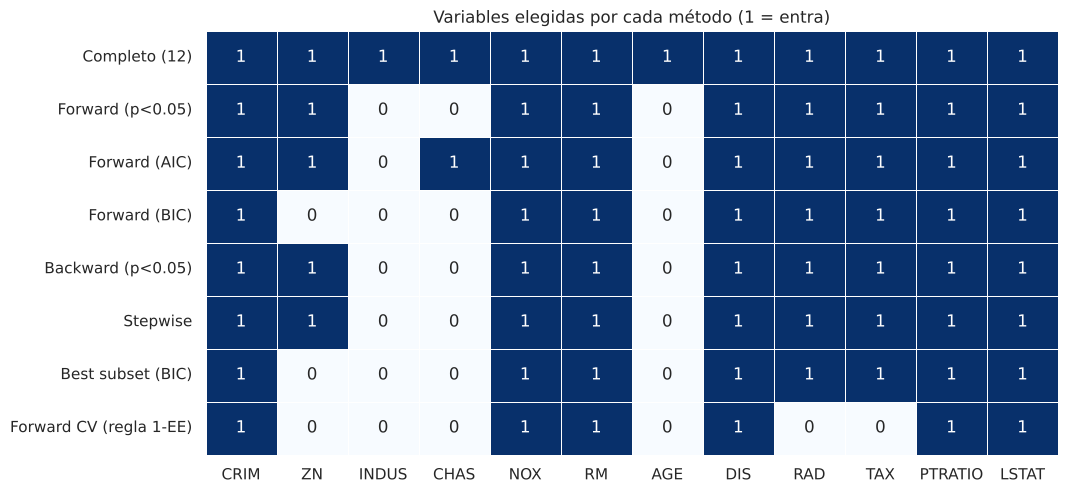

In [33]:
# ¿Qué variables eligió cada método? (matriz de presencia)
presencia = pd.DataFrame({n: [v in vars_ for v in PREDICTORES] for n, vars_ in candidatos.items()},
                         index=PREDICTORES).astype(int)
plt.figure(figsize=(11, 5.5))
sns.heatmap(presencia.T, cmap="Blues", cbar=False, linewidths=.5, linecolor="white", annot=True, fmt="d")
plt.title("Variables elegidas por cada método (1 = entra)"); plt.xlabel(""); plt.show()

### ¿Qué aprendimos de la comparación?

1. **Hay un núcleo estable**: `LSTAT`, `PTRATIO`, `RM`, `CRIM`, `DIS`, `NOX`, `RAD` aparecen en casi todos los métodos. Esas son las variables en las que podemos confiar más.
2. **`INDUS` y `AGE` nunca entran**: su información ya está contenida en otras (`NOX`, `DIS`).
3. Las diferencias están en los **márgenes** (`ZN`, `CHAS`, `TAX`), justamente donde los criterios están casi empatados.
4. En el conjunto de **prueba**, los modelos reducidos predicen **prácticamente igual** que el completo (diferencias de décimas de mil USD en el RMSE) con 3 a 6 variables menos → ganamos parsimonia sin sacrificar capacidad predictiva.

---
# PARTE 13. ⚠️ Advertencias: lo que la selección automática NO le dice

## 13.1 Los $p$-valores del modelo final son demasiado optimistas

Tras seleccionar, los $p$-valores del `summary()` **no** tienen su significado habitual: se calcularon como si el modelo hubiese sido fijado de antemano, pero en realidad **elegimos** las variables precisamente porque tenían $p$ pequeños.

**Experimento:** generamos una respuesta de **puro ruido** (ninguna variable tiene relación real) y aplicamos *forward*.

In [34]:
rng = np.random.default_rng(7)
n_sim, k_sim = 100, 40
X_ruido = pd.DataFrame(rng.normal(size=(n_sim, k_sim)), columns=[f"Z{i+1}" for i in range(k_sim)])
X_ruido["y_ruido"] = rng.normal(size=n_sim)                 # ¡no depende de nada!

vars_ruido, _ = seleccion_forward(X_ruido, "y_ruido", [f"Z{i+1}" for i in range(k_sim)], alfa_entrada=0.05, verbose=False)
m_ruido = smf.ols("y_ruido ~ " + " + ".join(vars_ruido), data=X_ruido).fit()
print(f"Variables 'significativas' encontradas en datos de PURO RUIDO: {vars_ruido}")
print(m_ruido.summary().tables[1])
print(f"\nPrueba F global: p = {m_ruido.f_pvalue:.4f}")

Variables 'significativas' encontradas en datos de PURO RUIDO: ['Z22', 'Z20', 'Z18', 'Z4', 'Z29', 'Z24']
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1114      0.082      1.352      0.180      -0.052       0.275
Z22           -0.2590      0.071     -3.665      0.000      -0.399      -0.119
Z20            0.2260      0.089      2.526      0.013       0.048       0.404
Z18            0.3328      0.083      4.025      0.000       0.169       0.497
Z4            -0.2419      0.084     -2.879      0.005      -0.409      -0.075
Z29           -0.1769      0.082     -2.149      0.034      -0.340      -0.013
Z24           -0.2068      0.103     -2.002      0.048      -0.412      -0.002

Prueba F global: p = 0.0000


😱 *Forward* "descubrió" variables con $p<0.05$ y una prueba $F$ global significativa… **en datos sin ninguna relación real**. Con 40 candidatos y $\alpha=0.05$, ya esperaríamos unos $2$ falsos positivos por azar si hiciéramos una sola prueba por variable; el proceso secuencial, que en cada paso **elige la mejor de muchas**, encuentra todavía más.

> **Moraleja:** los $p$-valores y los intervalos de confianza del modelo seleccionado deben reportarse con cautela. Para inferencia confirmatoria, las variables deben definirse **antes** de ver los datos (por teoría), o validarse en una muestra independiente.

## 13.2 La selección es inestable

Si la muestra cambiara un poco, ¿obtendríamos las mismas variables? Lo averiguamos con **bootstrap**: remuestreamos los datos de entrenamiento 100 veces y repetimos *forward*.

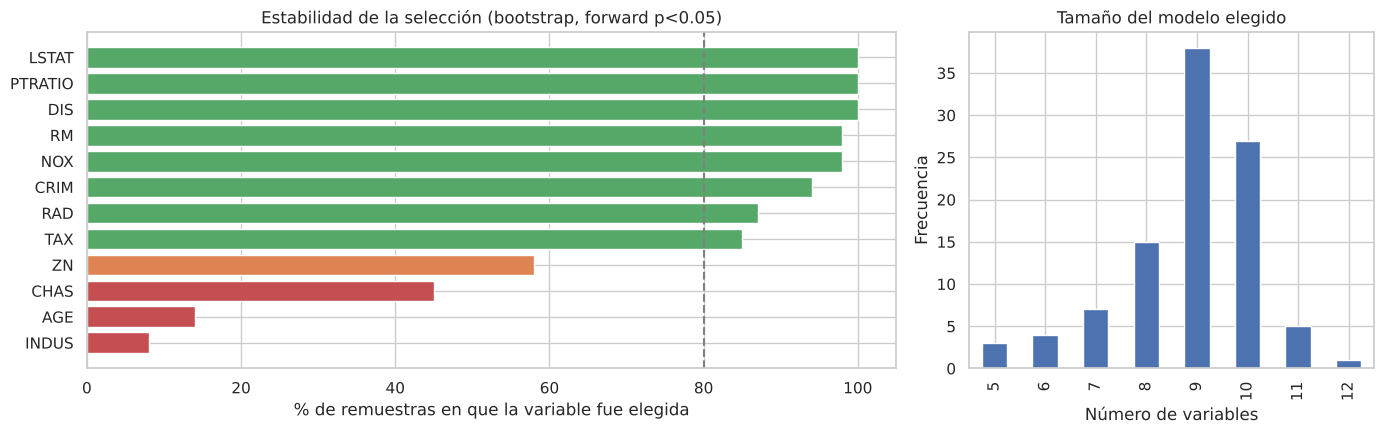

In [35]:
B = 100        # ✏️ puede subir a 300 si tiene tiempo
frecuencia = pd.Series(0, index=PREDICTORES, dtype=float)
tamanos = []
for b in range(B):
    muestra = train.sample(frac=1, replace=True, random_state=b)
    v, _ = seleccion_forward(muestra, Y, PREDICTORES, criterio="p", alfa_entrada=0.05, verbose=False)
    frecuencia[v] += 1
    tamanos.append(len(v))
frecuencia = (100 * frecuencia / B).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
colores = ["C2" if f >= 80 else ("C1" if f >= 50 else "C3") for f in frecuencia]
axes[0].barh(frecuencia.index, frecuencia.values, color=colores)
axes[0].axvline(80, ls="--", c="gray"); axes[0].set_xlabel("% de remuestras en que la variable fue elegida")
axes[0].set_title("Estabilidad de la selección (bootstrap, forward p<0.05)")
pd.Series(tamanos).value_counts().sort_index().plot.bar(ax=axes[1], color="C0")
axes[1].set(title="Tamaño del modelo elegido", xlabel="Número de variables", ylabel="Frecuencia")
plt.tight_layout(); plt.show()

**Lectura:** las variables en **verde** (≥80 %) son robustas; las de **naranja/rojo** entran o no según la muestra. Reportar la frecuencia de selección es una buena práctica que da transparencia sobre la incertidumbre del modelo.

## 13.3 Resumen de advertencias

| Advertencia | Consecuencia | Qué hacer |
|---|---|---|
| $p$-valores tras selección | Optimistas, falsos positivos | Validar en datos nuevos; preferir variables definidas por teoría |
| Métodos voraces | Pueden no hallar el mejor modelo | Comparar con búsqueda exhaustiva o varios métodos |
| Colinealidad | Cuál de dos variables redundantes entra es casi azar | Revisar VIF y correlaciones; decidir con criterio sustantivo |
| Inestabilidad | El modelo cambia con la muestra | Bootstrap de la selección |
| Seleccionar ≠ causalidad | Una variable excluida puede ser causalmente importante | Usar diagramas causales si el objetivo es explicar |

> 🔭 **Para seguir estudiando:** los métodos de **regularización** (Ridge, Lasso, Elastic Net) seleccionan y estiman al mismo tiempo, y suelen ser más estables. Están desarrollados en `Cuadernillo_Regresion_Lineal_Multiple.ipynb` (Parte 12).

---
# PARTE 14. El modelo final

### ✏️ Decisión

Con base en la evidencia:
- El núcleo estable aparece en todos los métodos.
- *Forward*, *backward* y *stepwise* con $p<0.05$ coinciden.
- BIC prefiere un modelo de tamaño similar y las curvas están casi empatadas.
- En prueba, el modelo reducido predice casi tan bien como el completo, con 3 variables menos.

Elegimos el modelo de **stepwise** (puede cambiarlo y comparar).

In [36]:
VARIABLES_FINALES = vars_step       # ✏️ puede reemplazar por otra lista, p. ej. mejor_bic
formula_final = f"{Y} ~ " + " + ".join(VARIABLES_FINALES)
modelo_final = smf.ols(formula_final, data=train).fit()
print(formula_final)
print(modelo_final.summary())

logMEDV ~ LSTAT + PTRATIO + RM + CRIM + DIS + NOX + RAD + TAX + ZN
                            OLS Regression Results                            
Dep. Variable:                logMEDV   R-squared:                       0.788
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     162.5
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          1.04e-126
Time:                        17:04:08   Log-Likelihood:                 116.59
No. Observations:                 404   AIC:                            -213.2
Df Residuals:                     394   BIC:                            -173.2
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------

## 14.1 Diagnóstico del modelo final

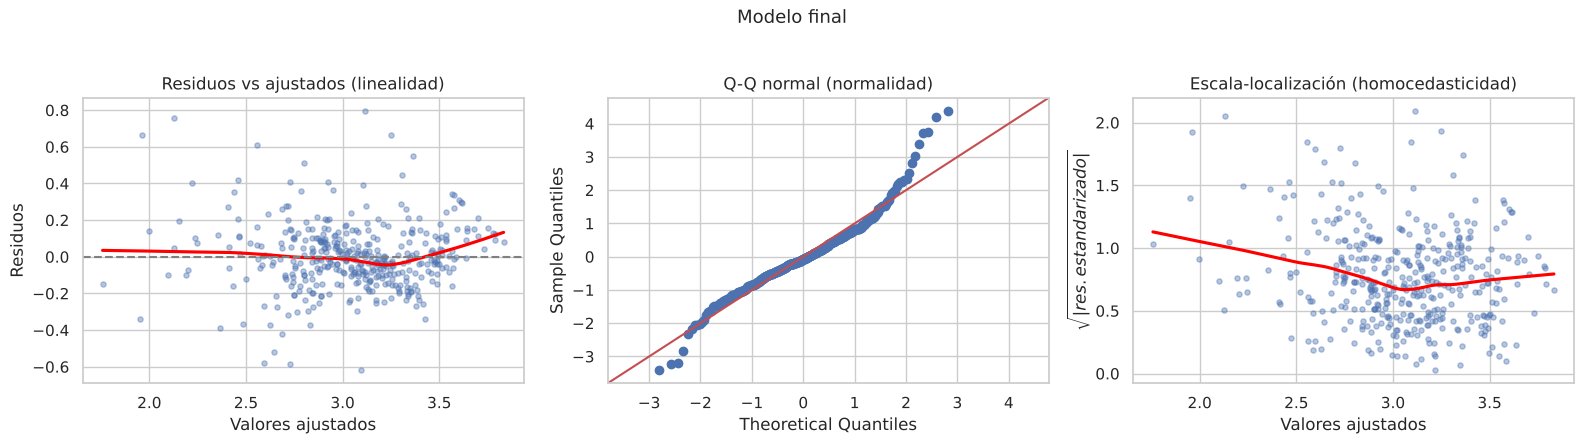

Breusch-Pagan (H0: varianza constante): p = 3.613e-07
Shapiro-Wilk  (H0: normalidad):         p = 1.185e-09



,variable,VIF
0,TAX,7.6532
1,RAD,7.4842
2,NOX,3.5282
3,DIS,3.2231
4,LSTAT,2.6535
5,CRIM,2.3087
6,ZN,2.1672
7,RM,1.8105
8,PTRATIO,1.7231


In [37]:
graficos_diagnostico(modelo_final, "Modelo final")
print()
tabla_vif(train[VARIABLES_FINALES])

Persiste algo de heterocedasticidad. Una solución estándar es reportar **errores estándar robustos (HC3)**: los coeficientes no cambian, pero sus errores estándar y $p$-valores se corrigen para varianza no constante.

In [38]:
modelo_final_robusto = smf.ols(formula_final, data=train).fit(cov_type="HC3")

tabla_final = pd.DataFrame({
    "coef": modelo_final.params,
    "ee_clásico": modelo_final.bse,
    "ee_robusto_HC3": modelo_final_robusto.bse,
    "p_robusto": modelo_final_robusto.pvalues,
    "efecto_%_en_MEDV": 100 * (np.exp(modelo_final.params) - 1),
}).drop("Intercept")
tabla_final.style.format({"coef": "{:.4f}", "ee_clásico": "{:.4f}", "ee_robusto_HC3": "{:.4f}",
                          "p_robusto": "{:.2e}", "efecto_%_en_MEDV": "{:+.2f} %"})

,coef,ee_clásico,ee_robusto_HC3,p_robusto,efecto_%_en_MEDV
LSTAT,-0.0289,0.0021,0.0037,3.97e-15,-2.85 %
PTRATIO,-0.0385,0.0056,0.0047,4.09e-16,-3.78 %
RM,0.0817,0.0172,0.0289,4.78e-03,+8.51 %
CRIM,-0.0147,0.0021,0.0029,5.21e-07,-1.46 %
DIS,-0.0565,0.0078,0.0090,4.02e-10,-5.49 %
NOX,-0.7340,0.1478,0.1643,7.89e-06,-52.00 %
RAD,0.0168,0.0029,0.0028,3.89e-09,+1.69 %
TAX,-0.0007,0.0002,0.0001,1.49e-08,-0.07 %
ZN,0.0014,0.0006,0.0005,4.44e-03,+0.14 %


## 14.2 Interpretación (ejemplos)

Recordemos que la respuesta es $\log(\text{MEDV})$, por lo que $100(e^{\beta_j}-1)$ es el **cambio porcentual** en el valor mediano por cada unidad adicional de $X_j$, **manteniendo constantes las demás variables del modelo**:

- **`RM`**: una habitación promedio más se asocia con un aumento de alrededor del **8.5 %** en el valor mediano.
- **`LSTAT`**: cada punto porcentual adicional de población de bajo estatus se asocia con una **disminución cercana al 2.9 %**.
- **`CRIM`**: cada unidad adicional en la tasa de criminalidad se asocia con una disminución de alrededor del **1.5 %**.
- **`NOX`**: el coeficiente parece enorme (−52 % "por unidad") porque `NOX` sólo varía entre 0.39 y 0.87. Una unidad no tiene sentido: es mejor decir que **un aumento de 0.1** en `NOX` se asocia con una disminución de cerca del **7 %** ($100(e^{-0.734\times0.1}-1)$). *Siempre interprete en unidades realistas de la variable.*

(Los valores exactos aparecen en la tabla anterior; si cambia `VARIABLES_FINALES`, cambiarán.)

> ⚠️ Son **asociaciones**, no efectos causales. Los datos son observacionales.

## 14.3 Desempeño en el conjunto de prueba

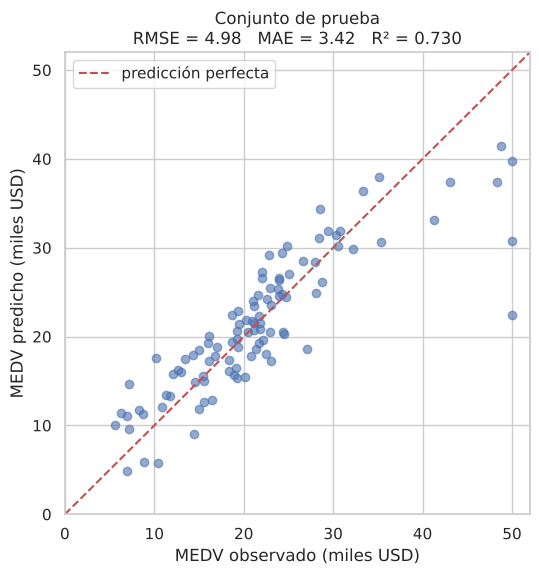

In [39]:
pred = np.exp(modelo_final.predict(test)) * np.mean(np.exp(modelo_final.resid))
rmse = np.sqrt(np.mean((test.MEDV - pred) ** 2))
mae = np.mean(np.abs(test.MEDV - pred))
r2_test = 1 - np.sum((test.MEDV - pred) ** 2) / np.sum((test.MEDV - test.MEDV.mean()) ** 2)

plt.figure(figsize=(6, 6))
plt.scatter(test.MEDV, pred, alpha=.6)
lim = [0, 52]; plt.plot(lim, lim, "r--", label="predicción perfecta")
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("MEDV observado (miles USD)"); plt.ylabel("MEDV predicho (miles USD)")
plt.title(f"Conjunto de prueba\nRMSE = {rmse:.2f}   MAE = {mae:.2f}   R² = {r2_test:.3f}")
plt.legend(); plt.show()

**Lectura:** en promedio, el modelo se equivoca en unos pocos miles de dólares. Note que las viviendas con `MEDV = 50` (valor topado) quedan subestimadas: es la consecuencia de la censura que detectamos en el EDA.

---
# PARTE 15. 🧪 Ejercicio para el estudiante: `Cars93`

Repita el proceso con la base `Cars93.csv` (93 modelos de automóviles de 1993).

**Respuesta:** `Price` (precio en miles de USD). Candidatos sugeridos: `EngineSize`, `Horsepower`, `RPM`, `Rev.per.mile`, `Fuel.tank.capacity`, `Passengers`, `Length`, `Wheelbase`, `Width`, `Turn.circle`, `Weight`, `MPG.city`, `MPG.highway`, `Origin`.

**Preguntas guía:**
1. ¿Hay predictores que no deban entrar por razones obvias? (pista: `Min.Price` y `Max.Price`).
2. ¿Conviene modelar `Price` o `log(Price)`? Justifique con el diagnóstico del modelo completo.
3. Ejecute *forward*, *backward* y *stepwise*. ¿Coinciden?
4. ¿Qué pasa con `MPG.city` y `MPG.highway`, que están muy correlacionadas?
5. ¿Qué tan estable es la selección (bootstrap)?

La siguiente celda deja todo preparado:

In [40]:
cars = pd.read_csv(ruta_datos("Cars93.csv"), index_col=0)
# Los nombres con punto no funcionan en las fórmulas: los cambiamos por guion bajo
cars.columns = [c.replace(".", "_") for c in cars.columns]
cars["Origin_USA"] = (cars.Origin == "USA").astype(int)
cars["logPrice"] = np.log(cars.Price)

CAND_CARS = ["EngineSize", "Horsepower", "RPM", "Rev_per_mile", "Fuel_tank_capacity", "Passengers",
             "Length", "Wheelbase", "Width", "Turn_circle", "Weight", "MPG_city", "MPG_highway", "Origin_USA"]
cars_m = cars[["Price", "logPrice"] + CAND_CARS].dropna()
print(cars_m.shape)

# Ejemplo de arranque (descomente y complete):
# vars_cars, hist_cars = seleccion_forward(cars_m, "logPrice", CAND_CARS, criterio="p", alfa_entrada=0.05)
# vars_cars_b, _ = seleccion_backward(cars_m, "logPrice", CAND_CARS, alfa_salida=0.05)

(93, 16)


---
# Síntesis de la clase

| Método | Empieza con | Movimiento | Ventaja | Limitación |
|---|---|---|---|---|
| **Forward** | Modelo nulo | Sólo añade | Sirve aun si $k>n$; rápido | Lo que entra nunca sale |
| **Backward** | Modelo completo | Sólo quita | Considera todas las variables juntas desde el inicio | Requiere $n>k$; lo que sale nunca vuelve |
| **Stepwise** | Modelo nulo | Añade y quita | Corrige decisiones previas | Sigue siendo voraz; $p$-valores optimistas |
| **Best subset** | Todos los modelos | — | Encuentra el óptimo según el criterio | Inviable si $k$ es grande ($2^k$ modelos) |
| **Con validación cruzada** | Cualquiera | — | Se enfoca en predecir | Más costoso; puede ser variable |

### Las cinco ideas para llevarse

1. **Primero se mira, luego se modela, después se selecciona.** El EDA y el diagnóstico del modelo completo no son opcionales.
2. El $R^2$ no sirve para comparar modelos de distinto tamaño: use $R^2_{aj}$, AIC, BIC o validación cruzada.
3. *Forward*, *backward* y *stepwise* se basan en la **prueba $F$ parcial** entre modelos anidados.
4. Diferentes métodos y criterios dan modelos **parecidos pero no idénticos**: confíe en el **núcleo estable**.
5. Los $p$-valores después de seleccionar son **optimistas**: la selección automática es una herramienta exploratoria, no un sustituto del criterio del analista.

### Glosario rápido

- **Parsimonia:** preferir el modelo más simple que explique adecuadamente los datos.
- **Modelos anidados:** uno contiene todas las variables del otro y algunas más.
- **Algoritmo voraz (*greedy*):** toma la mejor decisión en cada paso, sin mirar el conjunto completo.
- **AIC / BIC:** criterios de información; ajuste penalizado por complejidad. Menor es mejor.
- **Fuga de información:** usar datos de prueba (directa o indirectamente) durante el entrenamiento.
- **Regla de un error estándar:** elegir el modelo más simple cuyo error está a menos de 1 EE del mínimo.

### Referencias
- James, G., Witten, D., Hastie, T. y Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.), cap. 6. Springer.
- Montgomery, D., Peck, E. y Vining, G. (2012). *Introduction to Linear Regression Analysis* (5.ª ed.), cap. 10. Wiley.
- Harrell, F. (2015). *Regression Modeling Strategies* (2.ª ed.), sec. 4.3 (*Variable selection*). Springer.
- Harrison, D. y Rubinfeld, D. (1978). Hedonic housing prices and the demand for clean air. *Journal of Environmental Economics and Management*, 5, 81–102.